<a href="https://colab.research.google.com/github/notpeoplebee/praktikum-ml-fem/blob/main/Praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Praktikum 1.1 - Persiapan Library (Modul Bab 1)

In [ ]:
# Menjalankan di Google Colab / Jupyter Notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Library berhasil dimuat.")

Library berhasil dimuat.



Di bagian ini saya memuat semua library yang diperlukan untuk pemrosesan data, pembuatan model, evaluasi, dan visualisasi sepanjang praktikum bab ini.

**Penjelasan Kode:**
- `import pandas as pd` & `import numpy as np`: Digunakan untuk mengelola dataframe dan melakukan operasi komputasi numerik.
- `import matplotlib.pyplot as plt`: Modul untuk membuat grafik atau visualisasi data.
- `load_iris`: Berfungsi untuk memuat dataset bunga Iris bawaan dari Scikit-Learn.
- `train_test_split`: Digunakan untuk memecah dataset menjadi data latih dan data uji.
- `KNeighborsClassifier`: Algoritma *K-Nearest Neighbors* yang digunakan untuk model klasifikasi.
- `accuracy_score`: Metrik untuk mengukur tingkat akurasi prediksi model.

**Penjelasan Output:**
Teks `"Library berhasil dimuat."` muncul tanpa adanya error *ModuleNotFoundError*, yang artinya seluruh library utama (Pandas, NumPy, Matplotlib, dan Scikit-Learn) sudah terpasang dengan baik dan siap digunakan.

### Praktikum 1.2 - Memuat Dataset Iris (Modul Bab 1)

In [ ]:
iris = load_iris(as_frame=True)
df = iris.frame
df['target_name'] = df['target'].map(dict(enumerate(iris.target_names)))

print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Di bagian ini saya memuat dataset Iris langsung dari `sklearn` dalam bentuk dataframe Pandas dan menambahkan kolom nama spesies agar lebih mudah dibaca.

**Penjelasan Kode:**
- `load_iris(as_frame=True)`: Memuat dataset Iris langsung ke dalam format Pandas DataFrame.
- `df['target'].map(...)`: Mengubah label angka (0, 1, 2) pada kolom target menjadi nama spesies aslinya (*setosa*, *versicolor*, *virginica*).
- `df.shape`: Mengetahui dimensi dataset (jumlah baris dan kolom).
- `df.head()`: Menampilkan 5 baris pertama dari dataset.

**Penjelasan Output:**
Output ukuran dataset menunjukkan `(150, 6)`, yang berarti dataset ini memiliki total 150 baris data bunga dan 6 kolom (termasuk fitur dan target).

### Praktikum 1.3 - Preprocessing: Eksplorasi Awal (Modul Bab 1)


In [ ]:
print(df.info())
print("\nJumlah data per kelas:")
print(df['target_name'].value_counts())

X = df[iris.feature_names]
y = df['target']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   target_name        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

Jumlah data per kelas:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Pada tahap ini, saya melakukan pengecekan struktur data secara keseluruhan, melihat distribusi kelas, serta memisahkan antara variabel fitur dan target.

**Penjelasan Kode:**
- `df.info()`: Menampilkan informasi tipe data pada setiap kolom dan mengecek apakah ada *missing value*.
- `df['target_name'].value_counts()`: Menghitung jumlah sampel data untuk masing-masing kelas spesies bunga.
- `X = df[iris.feature_names]`: Menyimpan kolom-kolom atribut/fitur (seperti panjang dan lebar sepal/petal) ke dalam variabel `X`.
- `y = df['target']`: Menyimpan kolom label kelas target ke dalam variabel `y`.

**Penjelasan Output:**
Menghasilkan informasi struktur tabel serta distribusi data per kelas yang menunjukkan bahwa jumlah data untuk setiap spesies bunga Iris terbagi rata (masing-masing 50 data).

### Praktikum 1.4 - Training Model (Modul Bab 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

print("Model berhasil dilatih pada", X_train.shape[0], "data latih.")

Model berhasil dilatih pada 120 data latih.


Di bagian ini, data dibagi menjadi data latih dan data uji, kemudian model KNN dilatih menggunakan data latih tersebut.

**Penjelasan Kode:**
- `train_test_split(..., test_size=0.2, stratify=y)`: Memecah data dengan rasio 80% untuk pelatihan dan 20% untuk pengujian, serta menjaga proporsi kelas tetap seimbang lewat parameter `stratify`.
- `KNeighborsClassifier(n_neighbors=3)`: Menginisialisasi model KNN dengan jumlah tetangga terdekat ($k$) sebanyak 3.
- `model.fit(X_train, y_train)`: Melatih model menggunakan data fitur (`X_train`) dan target (`y_train`).

**Penjelasan Output:**
Tercetak pesan bahwa model berhasil dilatih menggunakan sejumlah baris data latih (120 data dari total 150 data).

### Praktikum 1.5 - Evaluasi Model (Modul Bab 1)

In [ ]:
y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model pada data uji: {akurasi:.2%}")

Akurasi model pada data uji: 100.00%


Pada tahap ini, saya melakukan pengujian model pada data uji (`X_test`) dan menghitung tingkat akurasinya.

**Penjelasan Kode:**
- `model.predict(X_test)`: Meminta model untuk memprediksi kelas dari data uji yang belum pernah dilihat sebelumnya.
- `accuracy_score(y_test, y_pred)`: Membandingkan hasil prediksi model (`y_pred`) dengan label aslinya (`y_test`).
- `print(f"...")`: Mencetak nilai akurasi akhir dalam bentuk persentase dua angka dibelakang koma.

**Penjelasan Output:**
Menampilkan skor akurasi performa model KNN dalam mengenali jenis bunga pada data uji.

### Praktikum 1.6 - Visualisasi Sebaran Data (Modul Bab 1)


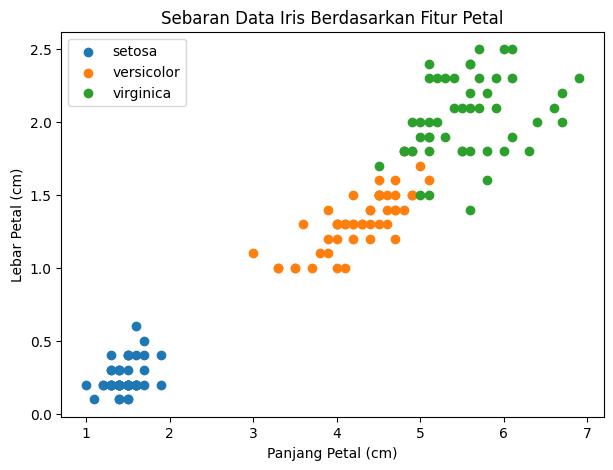

In [ ]:
plt.figure(figsize=(7,5))
for target_value, target_name in enumerate(iris.target_names):
    subset = df[df['target'] == target_value]
    plt.scatter(
        subset['petal length (cm)'],
        subset['petal width (cm)'],
        label=target_name
    )

plt.xlabel('Panjang Petal (cm)')
plt.ylabel('Lebar Petal (cm)')
plt.title('Sebaran Data Iris Berdasarkan Fitur Petal')
plt.legend()
plt.show()

Bagian terakhir ini bertujuan untuk memvisualisasikan sebaran data bunga Iris berdasarkan fitur ukuran petal menggunakan diagram scatter plot.

**Penjelasan Kode:**
- `plt.figure(figsize=(7,5))`: Mengatur ukuran kanvas gambar grafik.
- `for target_value, target_name in enumerate(iris.target_names)`: Melakukan perulangan untuk memisahkan titik-titik data berdasarkan masing-masing nama spesies.
- `plt.scatter(...)`: Membuat titik-titik sebaran (*scatter plot*) berdasarkan panjang dan lebar petal.
- `plt.xlabel`, `plt.ylabel`, `plt.title`: Memberikan keterangan label pada sumbu X, sumbu Y, dan judul grafik.
- `plt.legend()` & `plt.show()`: Menampilkan legenda warna spesies dan merender grafik ke layar.

**Penjelasan Output:**
Menghasilkan grafik sebaran (*scatter plot*) yang memperlihatkan kelompok titik-titik data untuk setiap kelas spesies bunga Iris berdasarkan fitur panjang dan lebar petal.